# TA-06 Random Forest: Prediksi Churn Nasabah Kartu Kredit
Dataset: Credit Card Customers (Kaggle), file BankChurners.csv (taruh di folder data/)
Target: Churn (1 = nasabah berhenti, 0 = nasabah masih aktif)

In [1]:
# 1. Import library
import os
import json
import warnings
import joblib
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.metrics import (accuracy_score, classification_report,
                             confusion_matrix, f1_score, roc_auc_score)

warnings.filterwarnings("ignore")
os.makedirs("model", exist_ok=True)
os.makedirs("static/img", exist_ok=True)
RANDOM_STATE = 42

In [2]:
# 2. Muat dataset
df = pd.read_csv("data/BankChurners.csv")
print("Ukuran data:", df.shape)
df.head()

Ukuran data: (10127, 23)


,CLIENTNUM,Attrition_Flag,Customer_Age,Gender,Dependent_count,Education_Level,Marital_Status,Income_Category,Card_Category,Months_on_book,...,Credit_Limit,Total_Revolving_Bal,Avg_Open_To_Buy,Total_Amt_Chng_Q4_Q1,Total_Trans_Amt,Total_Trans_Ct,Total_Ct_Chng_Q4_Q1,Avg_Utilization_Ratio,Naive_Bayes_Classifier_Attrition_Flag_Card_Category_Contacts_Count_12_mon_Dependent_count_Education_Level_Months_Inactive_12_mon_1,Naive_Bayes_Classifier_Attrition_Flag_Card_Category_Contacts_Count_12_mon_Dependent_count_Education_Level_Months_Inactive_12_mon_2
0,768805383,Existing Customer,45,M,3,High School,Married,$60K - $80K,Blue,39,...,12691.0,777,11914.0,1.335,1144,42,1.625,0.061,0.000093,0.99991
1,818770008,Existing Customer,49,F,5,Graduate,Single,Less than $40K,Blue,44,...,8256.0,864,7392.0,1.541,1291,33,3.714,0.105,0.000057,0.99994
2,713982108,Existing Customer,51,M,3,Graduate,Married,$80K - $120K,Blue,36,...,3418.0,0,3418.0,2.594,1887,20,2.333,0.000,0.000021,0.99998
3,769911858,Existing Customer,40,F,4,High School,Unknown,Less than $40K,Blue,34,...,3313.0,2517,796.0,1.405,1171,20,2.333,0.760,0.000134,0.99987
4,709106358,Existing Customer,40,M,3,Uneducated,Married,$60K - $80K,Blue,21,...,4716.0,0,4716.0,2.175,816,28,2.500,0.000,0.000022,0.99998


In [3]:
# 3. Eksplorasi dataset
print(df.info())
print("\nMissing value per kolom:")
print(df.isnull().sum())
print("\nData duplikat:", df.duplicated().sum())

<class 'pandas.DataFrame'>
RangeIndex: 10127 entries, 0 to 10126
Data columns (total 23 columns):
 #   Column                                                                                                                              Non-Null Count  Dtype  
---  ------                                                                                                                              --------------  -----  
 0   CLIENTNUM                                                                                                                           10127 non-null  int64  
 1   Attrition_Flag                                                                                                                      10127 non-null  str    
 2   Customer_Age                                                                                                                        10127 non-null  int64  
 3   Gender                                                                                      

In [4]:
# 4. Bersihkan kolom yang tidak dipakai dan buat target
# CLIENTNUM hanya ID, dua kolom Naive_Bayes bukan fitur asli
buang = ["CLIENTNUM"] + [c for c in df.columns if c.startswith("Naive_Bayes")]
df = df.drop(columns=buang)

df["Churn"] = (df["Attrition_Flag"] == "Attrited Customer").astype(int)
df = df.drop(columns=["Attrition_Flag"])
print("Jumlah kolom sekarang:", df.shape[1])

Jumlah kolom sekarang: 20


Churn
0    8500
1    1627
Name: count, dtype: int64
Churn
0    83.93
1    16.07
Name: proportion, dtype: float64


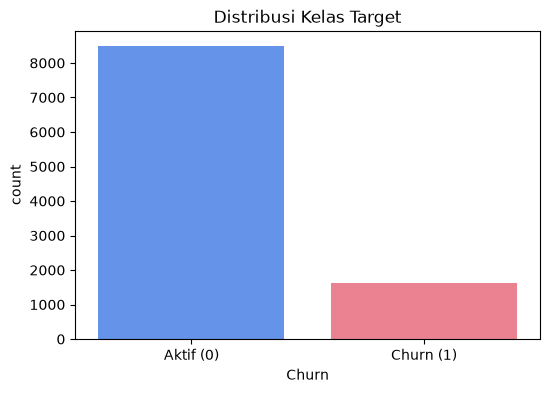

In [5]:
# 5. Cek ketidakseimbangan kelas (imbalance)
hitung = df["Churn"].value_counts()
persen = df["Churn"].value_counts(normalize=True) * 100
print(hitung)
print(persen.round(2))

plt.figure(figsize=(6, 4))
sns.countplot(x="Churn", data=df, palette=["#4f8cff", "#fb7185"])
plt.xticks([0, 1], ["Aktif (0)", "Churn (1)"])
plt.title("Distribusi Kelas Target")
plt.savefig("static/img/01_imbalance.png", dpi=150, bbox_inches="tight")
plt.show()

In [6]:
# 6. Pisahkan fitur dan target
X = df.drop(columns=["Churn"])
y = df["Churn"]

kolom_kat = X.select_dtypes(include="object").columns.tolist()
kolom_num = X.select_dtypes(exclude="object").columns.tolist()
print("Kategori :", kolom_kat)
print("Numerik  :", kolom_num)

# 7. Split data 80% latih, 20% uji (stratify supaya proporsi churn sama)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
print(X_train.shape, X_test.shape)

# 8. One-Hot Encoding untuk kolom kategori
def buat_prep():
    return ColumnTransformer(
        [("kat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), kolom_kat),
         ("num", "passthrough", kolom_num)],
        verbose_feature_names_out=False)

prep = buat_prep()
X_train_enc = prep.fit_transform(X_train)
X_test_enc = prep.transform(X_test)
print("Jumlah fitur setelah encoding:", len(prep.get_feature_names_out()))

Kategori : ['Gender', 'Education_Level', 'Marital_Status', 'Income_Category', 'Card_Category']
Numerik  : ['Customer_Age', 'Dependent_count', 'Months_on_book', 'Total_Relationship_Count', 'Months_Inactive_12_mon', 'Contacts_Count_12_mon', 'Credit_Limit', 'Total_Revolving_Bal', 'Avg_Open_To_Buy', 'Total_Amt_Chng_Q4_Q1', 'Total_Trans_Amt', 'Total_Trans_Ct', 'Total_Ct_Chng_Q4_Q1', 'Avg_Utilization_Ratio']
(8101, 19) (2026, 19)
Jumlah fitur setelah encoding: 37


   n_estimators  acc_train  acc_test  f1_churn
0            10     0.9972    0.9418    0.8127
1            50     0.9986    0.9566    0.8621
2           100     0.9988    0.9541    0.8554
3           200     0.9990    0.9526    0.8500
4           500     0.9993    0.9521    0.8496


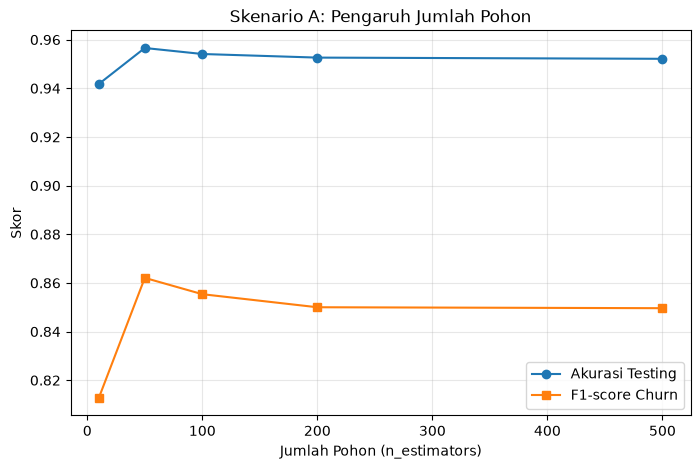

n_estimators terbaik: 50


In [7]:
# 9. Skenario A: pengaruh jumlah pohon (n_estimators)
daftar_n = [10, 50, 100, 200, 500]
hasil_a = []

for n in daftar_n:
    rf = RandomForestClassifier(n_estimators=n, class_weight="balanced",
                                random_state=RANDOM_STATE, n_jobs=-1)
    rf.fit(X_train_enc, y_train)
    pred = rf.predict(X_test_enc)
    hasil_a.append({
        "n_estimators": n,
        "acc_train": accuracy_score(y_train, rf.predict(X_train_enc)),
        "acc_test": accuracy_score(y_test, pred),
        "f1_churn": f1_score(y_test, pred),
    })

df_a = pd.DataFrame(hasil_a)
print(df_a.round(4))

# 10. Grafik garis Skenario A
plt.figure(figsize=(8, 5))
plt.plot(df_a["n_estimators"], df_a["acc_test"], marker="o", label="Akurasi Testing")
plt.plot(df_a["n_estimators"], df_a["f1_churn"], marker="s", label="F1-score Churn")
plt.xlabel("Jumlah Pohon (n_estimators)")
plt.ylabel("Skor")
plt.title("Skenario A: Pengaruh Jumlah Pohon")
plt.grid(alpha=0.3)
plt.legend()
plt.savefig("static/img/02_skenario_a.png", dpi=150, bbox_inches="tight")
plt.show()

# 11. Pilih n_estimators terbaik (akurasi testing tertinggi, kalau sama ambil yang terkecil)
best_n = int(df_a.loc[df_a["acc_test"].idxmax(), "n_estimators"])
print("n_estimators terbaik:", best_n)

### Analisis Skenario A
(Tulis sendiri dari hasil tabel dan grafik: apakah menambah pohon terus-menerus
meningkatkan akurasi secara signifikan? Mulai di jumlah pohon berapa grafik landai?)

   max_depth  acc_train  acc_test  selisih
0  Unlimited     0.9986    0.9566   0.0421
1          3     0.8369    0.8391  -0.0022
2          5     0.8983    0.8949   0.0034
3         10     0.9774    0.9452   0.0322
4         20     0.9981    0.9551   0.0431


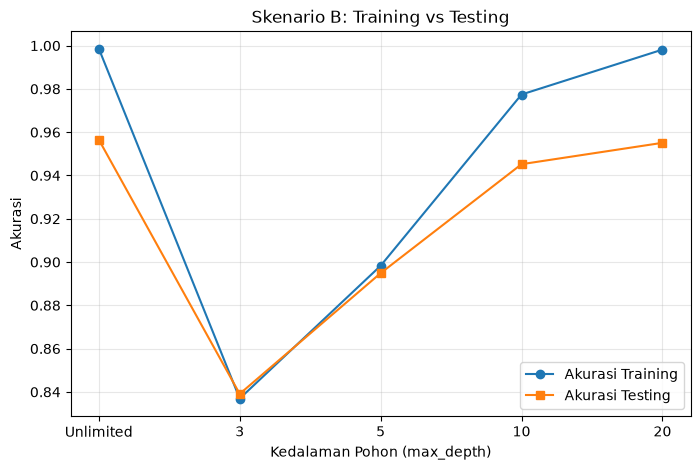

max_depth terbaik: Unlimited


In [8]:
# 12. Skenario B: pengaruh kedalaman pohon (max_depth)
daftar_depth = [None, 3, 5, 10, 20]
hasil_b = []

for d in daftar_depth:
    rf = RandomForestClassifier(n_estimators=best_n, max_depth=d,
                                class_weight="balanced",
                                random_state=RANDOM_STATE, n_jobs=-1)
    rf.fit(X_train_enc, y_train)
    tr = accuracy_score(y_train, rf.predict(X_train_enc))
    te = accuracy_score(y_test, rf.predict(X_test_enc))
    hasil_b.append({
        "max_depth": "Unlimited" if d is None else str(d),
        "acc_train": tr,
        "acc_test": te,
        "selisih": tr - te,
    })

df_b = pd.DataFrame(hasil_b)
print(df_b.round(4))

# 13. Grafik garis Training vs Testing
plt.figure(figsize=(8, 5))
plt.plot(df_b["max_depth"], df_b["acc_train"], marker="o", label="Akurasi Training")
plt.plot(df_b["max_depth"], df_b["acc_test"], marker="s", label="Akurasi Testing")
plt.xlabel("Kedalaman Pohon (max_depth)")
plt.ylabel("Akurasi")
plt.title("Skenario B: Training vs Testing")
plt.grid(alpha=0.3)
plt.legend()
plt.savefig("static/img/03_skenario_b.png", dpi=150, bbox_inches="tight")
plt.show()

# 14. Pilih max_depth terbaik (akurasi testing tertinggi, selisih train-test terkecil)
urut = df_b.assign(acc_r=df_b["acc_test"].round(3)).sort_values(
    ["acc_r", "selisih"], ascending=[False, True])
idx_best = urut.index[0]
best_depth = daftar_depth[idx_best]
print("max_depth terbaik:", df_b.loc[idx_best, "max_depth"])

### Analisis Skenario B
(Tulis sendiri: pada kedalaman berapa akurasi training naik terus tapi testing
stagnan atau turun? Itu tanda mulai overfitting.)

In [9]:
# 15. Model terbaik (pipeline: encoding + Random Forest)
model = Pipeline([
    ("prep", buat_prep()),
    ("rf", RandomForestClassifier(n_estimators=best_n, max_depth=best_depth,
                                  class_weight="balanced",
                                  random_state=RANDOM_STATE, n_jobs=-1)),
])
model.fit(X_train, y_train)

# 16. Evaluasi model terbaik
y_pred = model.predict(X_test)
y_proba = model.predict_proba(X_test)[:, 1]
acc = accuracy_score(y_test, y_pred)
auc = roc_auc_score(y_test, y_proba)

print("Akurasi Training:", accuracy_score(y_train, model.predict(X_train)))
print("Akurasi Testing :", acc)
print("ROC AUC         :", auc)
print("\nLaporan Klasifikasi:\n",
      classification_report(y_test, y_pred, target_names=["Aktif", "Churn"]))

Akurasi Training: 0.9986421429453154
Akurasi Testing : 0.9565646594274433
ROC AUC         : 0.9830570252792475

Laporan Klasifikasi:
               precision    recall  f1-score   support

       Aktif       0.97      0.98      0.97      1701
       Churn       0.88      0.85      0.86       325

    accuracy                           0.96      2026
   macro avg       0.92      0.91      0.92      2026
weighted avg       0.96      0.96      0.96      2026



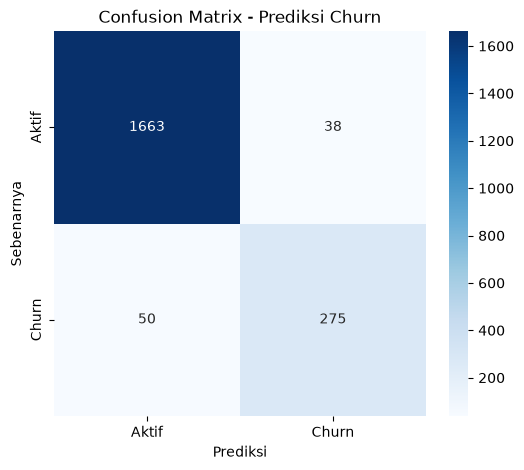

In [10]:
# 17. Confusion matrix
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Aktif", "Churn"], yticklabels=["Aktif", "Churn"])
plt.xlabel("Prediksi")
plt.ylabel("Sebenarnya")
plt.title("Confusion Matrix - Prediksi Churn")
plt.savefig("static/img/04_confusion_matrix.png", dpi=150, bbox_inches="tight")
plt.show()

                     Feature  Importance
33           Total_Trans_Amt    0.207237
34            Total_Trans_Ct    0.201400
30       Total_Revolving_Bal    0.100153
35       Total_Ct_Chng_Q4_Q1    0.089810
36     Avg_Utilization_Ratio    0.065057
32      Total_Amt_Chng_Q4_Q1    0.057485
26  Total_Relationship_Count    0.048722
27    Months_Inactive_12_mon    0.033190
31           Avg_Open_To_Buy    0.028367
29              Credit_Limit    0.028006


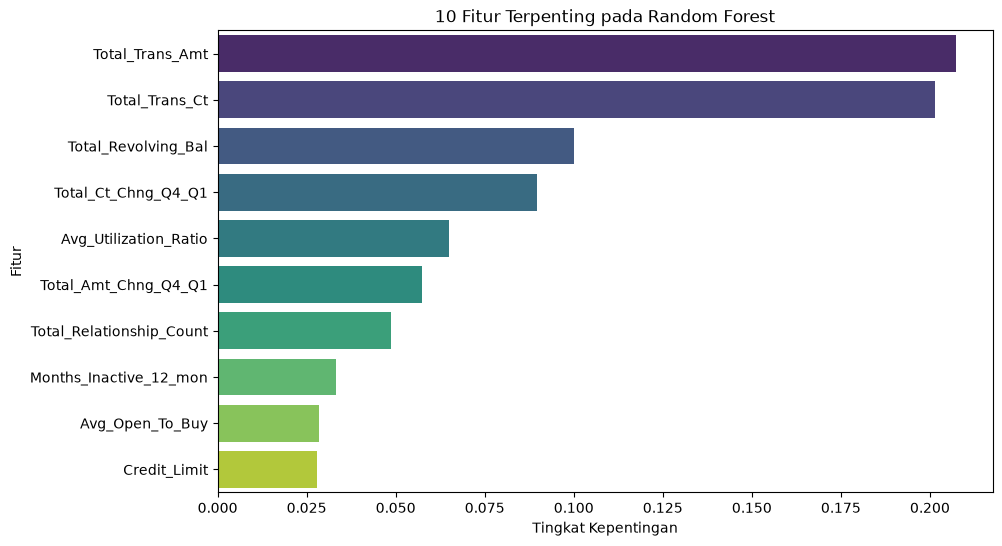

In [11]:
# 18. Feature importance 10 fitur teratas
nama = model.named_steps["prep"].get_feature_names_out()
penting = model.named_steps["rf"].feature_importances_
imp = pd.DataFrame({"Feature": nama, "Importance": penting})
imp = imp.sort_values("Importance", ascending=False)
top10 = imp.head(10)
print(top10)

plt.figure(figsize=(10, 6))
sns.barplot(x=top10["Importance"], y=top10["Feature"], palette="viridis")
plt.xlabel("Tingkat Kepentingan")
plt.ylabel("Fitur")
plt.title("10 Fitur Terpenting pada Random Forest")
plt.savefig("static/img/05_feature_importance.png", dpi=150, bbox_inches="tight")
plt.show()

### Interpretasi Feature Importance dan Business Insight
(Tulis sendiri: kenapa fitur teratas berpengaruh terhadap churn, apakah masuk akal
dengan teori perbankan, dan tindakan apa yang bisa dilakukan bank.)

In [12]:
# 19. Ambil contoh nasabah untuk tombol contoh di web
pos_risiko = int(np.argmax(y_proba))
pos_aman = int(np.argmin(y_proba))
contoh = {
    "berisiko": X_test.iloc[pos_risiko].to_dict(),
    "aman": X_test.iloc[pos_aman].to_dict(),
}

# 20. Simpan model dan metadata untuk web
joblib.dump(model, "model/rf_churn.joblib")

laporan = classification_report(y_test, y_pred,
                                target_names=["Aktif", "Churn"], output_dict=True)
meta = {
    "feature_order": X.columns.tolist(),
    "cat_cols": {c: sorted(df[c].unique().tolist()) for c in kolom_kat},
    "num_cols": {c: {"min": float(df[c].min()),
                     "max": float(df[c].max()),
                     "median": float(df[c].median())} for c in kolom_num},
    "n_data": int(len(df)),
    "n_fitur": int(X.shape[1]),
    "imbalance": {"aktif": int(hitung[0]), "churn": int(hitung[1])},
    "best": {"n_estimators": best_n, "max_depth": df_b.loc[idx_best, "max_depth"]},
    "metrics": {"accuracy": float(acc), "roc_auc": float(auc), "report": laporan},
    "confusion_matrix": cm.tolist(),
    "scenario_a": df_a.round(4).to_dict(orient="records"),
    "scenario_b": df_b.round(4).to_dict(orient="records"),
    "importance_top10": top10.round(4).to_dict(orient="records"),
    "contoh": contoh,
}

with open("model/meta.json", "w", encoding="utf-8") as f:
    json.dump(meta, f, indent=2, ensure_ascii=False,
              default=lambda o: o.item() if hasattr(o, "item") else str(o))
print("Model dan meta.json tersimpan")

# 21. Tes model yang tersimpan
tes = joblib.load("model/rf_churn.joblib")
print(tes.predict_proba(X_test.iloc[[0]]))

Model dan meta.json tersimpan
[[0.96 0.04]]


### Kesimpulan
(Tulis sendiri: kombinasi n_estimators dan max_depth yang paling stabil,
akurasi dan F1 churn model terbaik, serta fitur kunci.)